# Foundation

Foundation is a library built in the portfolio which each system imports as its base. The tools imported include various statistical validation techniques (including Block bootstrap of Sharpe ratio, which is the primary test used), alongside walk-forward methods and portfolio optimisation tools. Here, some of them are showcased, with the primary crypto project, absolute momentum, called M0.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent                
sys.path.insert(0, str(ROOT / "src"))
import foundation

CRYPTO = ROOT.parent / "crypto_portfolio"
m0 = pd.read_csv(CRYPTO / "crypto_momentum" / "results" / "momentum_30d_within_hour_daily_returns.csv", parse_dates=["Date"], index_col="Date")["momentum_30d"]
print(len(foundation.__all__), "public functions and classes")
print("M0:", m0.index.min().date(), "to", m0.index.max().date())

116 public functions and classes
M0: 2019-07-01 to 2026-09-22


## 1. Sharpe ratio, block bootstrap

The 'paired bootstrap' function resamples each returns series with the same blocks, retaining the same correlations and dependency between strategy and benchmark, allowing for a more proper statistical comparison.  Its bounds are one sided, hence level=0.975 gives a two sided 95% confidence interval. It is applied below, testing M0 with a 30% volatility target against its original version.


In [ ]:
scale = foundation.vol_target(m0, target=0.30, window=60, periods_per_year=365, max_leverage=1.0)["scale"]
pair = pd.DataFrame({"vol-targeted": scale * m0, "M0": m0}).dropna()
pair["window"] = np.where(pair.index < "2024-01-01", "development (to 2023)", "holdout (2024 on)")
rows = {}
for win, g in pair.groupby("window"):
    res = foundation.paired_bootstrap(g["vol-targeted"], g["M0"], block_size=28, resamples=5000, seed=1, periods_per_year=365, level=0.975)
    rows[win] = {"days": len(g),
                 "vol-targeted Sharpe": foundation.sharpe(g["vol-targeted"], 365),
                 "M0 Sharpe": foundation.sharpe(g["M0"], 365),
                 "Sharpe difference": res["sharpe_difference"],
                 "95% lower": res["sharpe_lower"], "95% upper": res["sharpe_upper"]}

pd.DataFrame(rows).T.round(3)

,days,vol-targeted Sharpe,M0 Sharpe,Sharpe difference,95% lower,95% upper
development (to 2023),1548.0,1.531,1.525,0.006,-0.323,0.321
holdout (2024 on),986.0,1.113,1.115,-0.001,-0.174,0.186


## 2. Purged Walk Forward Periods

In [3]:
dates = m0.index[m0.index.dayofweek == 0]
label_end = dates + pd.Timedelta(days=30)
folds = list(foundation.walk_forward(dates, label_end, min_train=104, test_size=52, purge="0D", embargo="7D"))
pd.DataFrame([{"cutoff": f.cutoff.date(), "train weeks": len(f.train),
               "first test": dates[f.test[0]].date(), "last test": dates[f.test[-1]].date()} for f in folds])

,cutoff,train weeks,first test,last test
0,2022-06-20,151,2022-06-27,2023-06-19
1,2023-06-19,203,2023-06-26,2024-06-17
2,2024-06-17,255,2024-06-24,2025-06-16
3,2025-06-16,307,2025-06-23,2026-06-15
4,2026-06-15,359,2026-06-22,2026-09-21


## 3. Volatility targeting

The 'vol_target' function gives the weighting that takes a return source to the inputted target volatility, which is estimated on a chosen, trailing window, with a day lag to ensure only past data is used. This was tested on the absolute momentum approach and rejected, with the plot below showing why, we ended up cutting exposure more than risk. In calm periods, the scale wants leverage which is what the cap removes, and volatile periods lead to selling most of the holdings.

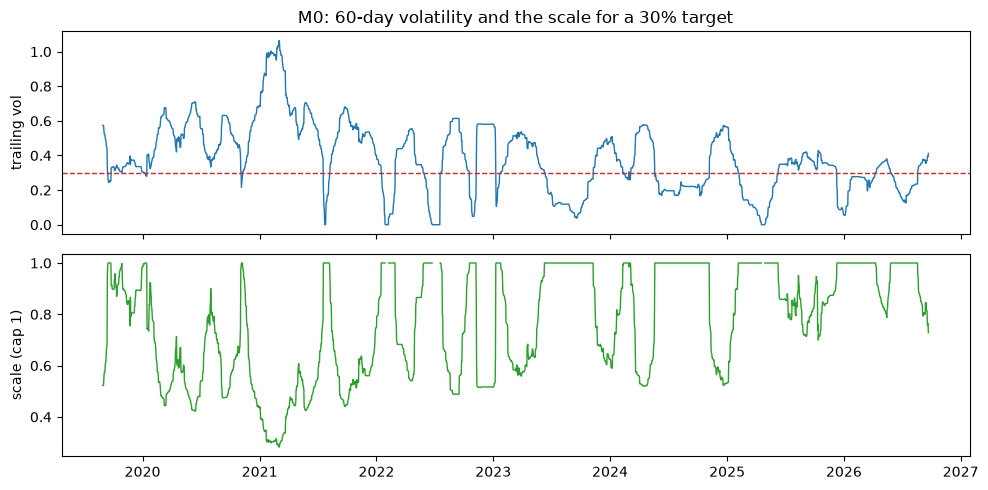

mean scale: 0.768


In [4]:
vt = foundation.vol_target(m0, target=0.30, window=60, periods_per_year=365, max_leverage=1.0)
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(vt["estimated_vol"], lw=1); ax[0].axhline(0.30, color="tab:red", ls="--", lw=1); ax[0].set_ylabel("trailing vol")
ax[1].plot(vt["scale"], lw=1, color="tab:green"); ax[1].set_ylabel("scale (cap 1)")
ax[0].set_title("M0: 60-day volatility and the scale for a 30% target")
plt.tight_layout(); plt.show()
print("mean scale:", round(vt["scale"].mean(), 3))

## 4. Multiple testing: Holm correction

When screening candidates, p-values need to be adjusted to account for the fact that not only 1 candidate is being tested, hence a significant result becomes much more likely. This is called 'Holm Adjusting', and is what the 'holm' function in foundation does, which is illustrated below.

In [5]:
p = np.array([0.0005, 0.007, 0.02, 0.04, 0.30])
adj, keep = foundation.holm(p, alpha=0.05)
pd.DataFrame({"raw p": p, "Holm adjusted": adj.round(4), "survives 5%": keep})

,raw p,Holm adjusted,survives 5%
0,0.0005,0.0025,True
1,0.0070,0.0280,True
2,0.0200,0.0600,False
3,0.0400,0.0800,False
4,0.3000,0.3000,False
